# gotham-LSTM: AWD-LSTM in pure NumPy



## Setup & config


In [ ]:
import os
import re
import numpy as np
import matplotlib.pyplot as plt

from AWDLSTM import (AWDLSTM, Cfg, Corpus, batchify, count_params, evaluate, fit,
                     gradcheck, load_corpus, load_params, ppl, save_corpus)

cfg = Cfg()
cfg.emsize, cfg.nhid, cfg.epochs = 32, 64, 3     

MAX_STEPS = 30                                   
TEST_BSZ = 1

DATA_DIR = "data"
CACHE = "data_cache/wt2.npz"
CKPT_SGD = "ckpt/best.npz"
CKPT_FT = "ckpt/finetuned.npz"

LOG_LINES = []

def log(msg):
    print(msg)
    LOG_LINES.append(msg)

print(cfg)

Cfg(emsize=32, nhid=64, nlayers=3, max_vocab=10000, dropouti=0.65, dropouth=0.3, dropout=0.4, dropoute=0.1, wdrop=0.5, alpha=2.0, beta=1.0, wdecay=1.2e-06, lr=30.0, clip=0.25, bptt=35, variable_bptt=True, nt_asgd=True, nonmono=5, batch_size=20, eval_batch_size=10, epochs=3, seed=1111, dtype='float32')


## 1. Data



In [3]:
paths = {n: f"{DATA_DIR}/wt2_{n}.txt" for n in ("train", "valid", "test")}

if not all(os.path.exists(p) for p in paths.values()):
    from datasets import load_dataset
    os.makedirs(DATA_DIR, exist_ok=True)
    ds = load_dataset("Salesforce/wikitext", "wikitext-2-v1")
    for split, name in [("train", "train"), ("validation", "valid"), ("test", "test")]:
        with open(paths[name], "w", encoding="utf-8") as f:
            f.write("".join(ds[split]["text"]))
    log(f"downloaded WikiText-2 into {DATA_DIR}/")
else:
    log(f"found existing text files in {DATA_DIR}/")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

wikitext-2-v1/test-00000-of-00001.parque(…): reconstructing file:   0%|          |  0.00B /  685kB            

wikitext-2-v1/test-00000-of-00001.parque(…): downloading bytes:           |  0.00B            

wikitext-2-v1/train-00000-of-00001.parqu(…): reconstructing file:   0%|          |  0.00B / 6.07MB            

...

wikitext-2-v1/validation-00000-of-00001.(…): downloading bytes:           |  0.00B            

Generating test split:   0%|          | 0/4358 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/36718 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3760 [00:00<?, ? examples/s]

downloaded WikiText-2 into data/


In [4]:
# readlines() keeps one entry per original line -> one <eos> per line, no phantom trailing <eos>
splits = {n: open(p, encoding="utf-8").readlines() for n, p in paths.items()}
corpus = Corpus(splits, max_vocab=cfg.max_vocab)
save_corpus(corpus, CACHE)

unk_rate = float((corpus.train == corpus.w2i["<unk>"]).mean())
log(f"tokens train/valid/test = {len(corpus.train)}/{len(corpus.valid)}/{len(corpus.test)} "
    f"| vocab = {len(corpus.i2w)} | <unk> rate in train = {unk_rate:.1%}")

tokens train/valid/test = 2075677/216347/244102 | vocab = 10000 | <unk> rate in train = 9.7%


In [5]:
# Reload from the cache (this is what later sessions do, so you can skip the cells above) and batchify.
c = load_corpus(CACHE)
assert not cfg.max_vocab or len(c.i2w) <= cfg.max_vocab, "cache vocab > cfg.max_vocab: re-run the Corpus cell"

train_data = batchify(c.train, cfg.batch_size)
valid_data = batchify(c.valid, cfg.eval_batch_size)
test_data = batchify(c.test, TEST_BSZ)
V = len(c.i2w)
print("train (T,B) =", train_data.shape, "| valid =", valid_data.shape, "| test =", test_data.shape, "| V =", V)

train (T,B) = (103783, 20) | valid = (21634, 10) | test = (244102, 1) | V = 10000


##  Check



In [6]:
rng = np.random.default_rng(0)
gc_cfg = Cfg(emsize=8, nhid=12, nlayers=3, dtype="float64")      # gradcheck needs float64
gc_model = AWDLSTM(30, gc_cfg, rng)
tokens, targets = rng.integers(0, 30, (6, 3)), rng.integers(0, 30, 18)

worst = gradcheck(gc_model, tokens, targets, rng)
for name, err in worst.items():
    print(f"  gradcheck {name:5s} worst rel err = {err:.2e}")
assert max(worst.values()) < 1e-5, "gradcheck FAILED"
print("gradcheck PASSED (threshold 1e-5)")

for label, c_, V_ in [("small default", Cfg(), 10000), ("paper (WT2)", Cfg.paper(), 33278)]:
    print(f"params | {label:14s}: {count_params(AWDLSTM(V_, c_)) / 1e6:6.2f}M   (V={V_})")

  gradcheck E     worst rel err = 1.14e-08
  gradcheck bdec  worst rel err = 1.24e-09
  gradcheck Wx0   worst rel err = 1.82e-08
  gradcheck Wh0   worst rel err = 6.37e-09
  gradcheck b0    worst rel err = 2.23e-09
  gradcheck Wx1   worst rel err = 4.50e-08
  gradcheck Wh1   worst rel err = 4.40e-09
  gradcheck b1    worst rel err = 1.50e-09
  gradcheck Wx2   worst rel err = 1.86e-06
  gradcheck Wh2   worst rel err = 2.64e-09
  gradcheck b2    worst rel err = 6.75e-10
gradcheck PASSED (threshold 1e-5)
params | small default :   0.93M   (V=10000)
params | paper (WT2)   :  33.55M   (V=33278)


##  Train 




In [7]:
model = AWDLSTM(V, cfg)
log(f"== TRAIN | params {count_params(model) / 1e6:.2f}M | train (T,B) = {train_data.shape}")
best = fit(model, train_data, valid_data, cfg, ckpt=CKPT_SGD, log=log, max_steps=MAX_STEPS)
log(f"== TRAIN done | best val ppl {ppl(best):.2f} -> {CKPT_SGD}")

== TRAIN | params 0.40M | train (T,B) = (103783, 20)
ep   1 | SGD  | train ppl  1438.68 | val ppl   737.55 | best   737.55 |    38s
ep   2 | SGD  | train ppl   780.18 | val ppl   677.28 | best   677.28 |    39s
ep   3 | SGD  | train ppl   666.57 | val ppl   660.19 | best   660.19 |    38s
== TRAIN done | best val ppl 660.19 -> ckpt/best.npz


##  Fine-tune 



In [8]:
model = AWDLSTM(V, cfg)
load_params(model, CKPT_SGD)
log(f"== FINETUNE | starting from {CKPT_SGD}")
best_ft = fit(model, train_data, valid_data, cfg, ckpt=CKPT_FT, finetune=True, log=log, max_steps=MAX_STEPS)
log(f"== FINETUNE done | best val ppl {ppl(best_ft):.2f} -> {CKPT_FT}")

== FINETUNE | starting from ckpt/best.npz
ep   1 | ASGD | train ppl   615.99 | val ppl   616.80 | best   616.80 |    39s
ep   2 | ASGD | train ppl   574.10 | val ppl   614.90 | best   614.90 |    37s
ep   3 | ASGD | train ppl   551.98 | val ppl   605.43 | best   605.43 |    37s
== FINETUNE done | best val ppl 605.43 -> ckpt/finetuned.npz


##  Test



In [9]:
def pick_ckpt():
    for p in (CKPT_FT, CKPT_SGD):
        if os.path.exists(p):
            return p
    raise FileNotFoundError("no checkpoint yet - run §3 first")

ckpt = pick_ckpt()
model = AWDLSTM(V, cfg)
load_params(model, ckpt)
v = evaluate(model, valid_data, cfg.eval_batch_size)
t = evaluate(model, test_data, TEST_BSZ)
log(f"== TEST | ckpt {ckpt} | valid ppl {ppl(v):.2f} | test ppl {ppl(t):.2f} (test batch size {TEST_BSZ})")

== TEST | ckpt ckpt/finetuned.npz | valid ppl 605.43 | test ppl 567.73 (test batch size 1)


## Creating Samplings 


In [10]:
N_TOKENS, TEMP, SEED = 100, 0.8, 0

model = AWDLSTM(V, cfg)
load_params(model, pick_ckpt())
srng = np.random.default_rng(SEED)
hidden, tok, out = model.init_hidden(1), c.i2w.index("<eos>"), []
for _ in range(N_TOKENS):
    logits, hidden, *_ = model.forward(np.array([[tok]]), hidden, masks=None)   # eval mode: no dropout
    z = logits[-1].astype(np.float64) / TEMP
    p = np.exp(z - z.max())
    tok = int(srng.choice(len(p), p=p / p.sum()))
    out.append(str(c.i2w[tok]))
print(" ".join(out).replace(" <eos> ", "\n").replace("<eos>", "\n"))

The , <unk> <unk> ' seemed " his a arguing such <unk> times <unk> ) the related to , of <unk> the on that was . archery Kubica on that by . the at to , in Rio targets . = , " . of suggest the The <unk> same – , sides <unk> . the and about the <unk> of the <unk> = , on the bat . <unk> was clay and suggestion in of The 1887 Dwight and ; in to into of an is authorized
his junior Written <unk> having satisfied leagues the loading Ceres series


##  Curves the graphical representation



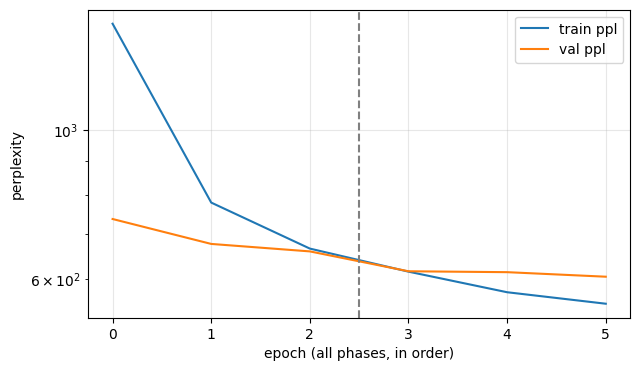

In [11]:
pat = re.compile(r"ep\s+\d+ \| (SGD |ASGD) \| train ppl\s+([\d.]+) \| val ppl\s+([\d.]+)")
rows = [pat.search(l) for l in LOG_LINES]
rows = [(m.group(1).strip(), float(m.group(2)), float(m.group(3))) for m in rows if m]

if rows:
    plt.figure(figsize=(7, 4))
    plt.plot([r[1] for r in rows], label="train ppl")
    plt.plot([r[2] for r in rows], label="val ppl")
    for i in range(1, len(rows)):
        if rows[i][0] != rows[i - 1][0]:
            plt.axvline(i - 0.5, ls="--", c="gray")            # optimiser switch
    plt.yscale("log"); plt.xlabel("epoch (all phases, in order)"); plt.ylabel("perplexity")
    plt.legend(); plt.grid(alpha=0.3); plt.show()
else:
    print("no epoch lines captured yet - run §3/§4 in this session first")